<a href="https://colab.research.google.com/github/crd10lop/Modelos-udea-cristian-diez/blob/main/MODELOS2_Aprendizaje_Automatico/LAB_06_02_Reducci%C3%B3n_de_dimensi%C3%B3n_PCA_y_LDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 6 - Parte 2: Reducción de dimensión PCA y LDA

In [ ]:
!wget -nc --no-cache -O init.py -q https://raw.githubusercontent.com/jdariasl/Intro_ML_2025/master/init.py
import init; init.init(force_download=False); init.get_weblink()

replicating local resources
replicating Labs resources


In [ ]:
from local.lib.rlxmoocapi import submit, session
import inspect

session.LoginSequence(
    endpoint=init.endpoint,
    course_id="introml",
    session_id="udea.vir.20262.g2",
    lab_id="L06.02",
    varname="student"
)

logging in as cristian.diez@udea.edu.co... please wait
you are registered in the following sessions of this course

     ['udea.vir.20261', 'udea.vir.20262.g2']

and you have explicitly requested session 'udea.vir.20262.g2'.
your grades will be reported in that session

-------------
using course session introml::udea.vir.20262.g2
success!! you are logged in
-------------


In [ ]:
#configuración del laboratorio
# Ejecuta esta celda!
from Labs.commons.utils.lab6 import *
_, x, y = part_2()

Para el problema de clasificación usaremos la siguiente base de datos: https://archive.ics.uci.edu/ml/datasets/Cardiotocography

Analice la base de datos, sus características, su variable de salida y el contexto del problema.

In [ ]:
print('Dimensiones de la base de datos de entrenamiento. dim de X: ' + str(np.shape(x)) + '\tdim de Y: ' + str(np.shape(y)))

Dimensiones de la base de datos de entrenamiento. dim de X: (2126, 22)	dim de Y: (2126,)


Este ejercicio tiene como objetivo implementar varias técnicas de extracción de características (PCA y LDA)

**observación para las librerias sklearn**

Llamar explicitamente los parametros de las librerias de sklearn (e.j. si se quiere usar el parametro `kernel` del `SVC`, se debe llamar `SVC(kernel='rbf'`)

En la siguiente celda se define una función para entrenar un SVM para resolver el problema. Esta función la vamos a usar como base para comparar nuestros métodos de selección de características.

In [ ]:
def entrenamiento_sin_seleccion_caracteristicas(splits, X, Y):
    """
    Función que ejecuta el entrenamiento del modelo sin una selección particular
    de las características

      Parámetros:
        splits : número de particiones  a realizar
      Retorna:
        - El vector de exactitudes
        - El Intervalo de confianza
        - El tiempo de procesamiento
    """
    #Implemetamos la metodología de validación
    Acc = np.ones(splits)
    Score = np.ones(splits)
    times = np.ones(splits)
    j = 0
    kf = KFold(n_splits=splits)
    for train_index, test_index in kf.split(X):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = Y[train_index], Y[test_index]
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
        #Creamos el clasificador SVM.
        clf = SVC(kernel="linear", C=1)
        #Aquí se entran y se valida el modelo sin hacer selección de características
        tiempo_i = time.time()
        clf.fit(X_train,y_train)
        # Validación del modelo
        Acc[j] = accuracy_score(y_true=y_test, y_pred=clf.predict(X_test))
        times[j] = time.time()-tiempo_i
        j+=1

    return np.mean(Acc), np.std(Acc), np.mean(times)

### Ejercicio 1: Entrenamiento usando PCA para realizar extracción

En este ejercicio vamos a aplicar PCA para realizar la extracción de características. Para ello se debe tener en cuenta:

1. Vamos a usar el módulo [PCA de sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), que ya se encuentra importado (se pueda acceder a el como `PCA(....)`)
2. Tener en cuenta la respuesta de la siguiente pregunta abierta y completar el código de acuerdo a la respuesta usando la librería y módulo de sklearn correspondiente (que también debería ya estar importado en la configuración).
3. Usar el parámetro adecuado para las particiones en la metodología de validación
3. Usar la exactitud como medida de error del módulo [metrics de sklearn](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.metrics)
4. Vamos a calcular el costo computacional de aplicar PCA.
5. Recordar que PCA se debe "ajustar" con el conjunto de entrenamiento. Pero la transformación se debe hacer para las particiones de entrenamiento y test.

In [ ]:
#@title Pregunta Abierta
#@markdown Cuando se aplica PCA ¿es necesario estandarizar los datos? ¿En qué consiste dicha estandarización?
respuesta = '' #@param {type:"string"}

In [ ]:
#ejercicio de código
def entrenamiento_pca_ext_caracteristicas(n_comp, n_sets, X, Y):
    """
    Esta función realiza la reducción de la dimensionalidad sobre el conjunto de
    datos de entrenamiento, de acuerdo con las particiones especificadas usando PCA

    Parámetros:
        n_comp, int, Número de componentes para reducción
        n_sets,int, Número de particiones
        X: numpy Array de características
        Y: numpy Array  Vector de etiquetas

    Retorna:
        El valor medio de errores
        Intervalo de confianza del error
        El  valor medio del tiempo de ejecución
    """
    #Implemetamos la metodología de validación
    Errores = np.zeros(n_sets)
    times = np.zeros(n_sets)
    j = 0
    kf = KFold(n_splits=n_sets)
    for train_index, test_index in kf.split(X):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = Y[train_index], Y[test_index]

        # ¿es necesario estandarizacion de datos?
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        #dejar el mismo nombre del objeto
        pca = PCA(n_components=n_comp)
        # para calcular costo computacional
        tiempo_i = time.time()
        # es recomendable usar el metodo que ajusta y transforma
        X_train_pca = pca.fit_transform(X_train)
        # aca solo usar el metodo de transformar (ya que en el anterior el pca se ajusto)
        X_test_pca = pca.transform(X_test)
        # entrenar el modelo usando las caractieristicas transformadas por PCA
        clf = SVC(kernel="linear", C=1)
        clf.fit(X=X_train_pca, y=y_train)
        tiempo_o = time.time()-tiempo_i
        Errores[j] = accuracy_score(y_true=y_test, y_pred=clf.predict(X_test_pca))
        times[j] = tiempo_o
        j+=1


    return np.mean(Errores), np.std(Errores), np.mean(times)

**Registra tu solución en línea**

In [ ]:
student.submit_task(namespace=globals(), task_id='T1');

### Ejercicio 2 : Experimentar con PCA

Usando las anteriores funciones vamos a realizar experimentos para evaluar la efectividad de PCA, para ello:

1. Utilizar una metodología cross-validation con 5 particiones.
2. Usar como parámetros para los experimentos el número de características a extraer
3. Usar la función `entrenamiento_pca_ext_caracteristicas` para realizar la extración de características.
3. Vamos a retornar un DataFrame con las siguientes columnas:
    - CON_SEL: indicando si se uso selección de características
    - NUM_VAR: número de selección de características
    - T_EJECUCION: tiempo de ejecucción
    - ERROR_VALIDACION
    - STD_ERROR_VALIDACION
4. En la primera fila del dataframe vamos a incluir la evaluación del modelo SVM sin selección de características (usando la función creada en el primer ejercicio).

In [ ]:
#ejercicio de código
def experimentar_PCA(n_feats, X, Y):
    """
    Esta función realiza la comparación del desempeño de PCA utilizando diferente
    número de caracteristicas y particionando el conjunto de datos en 5 conjuntos

    Parámetros:
        X (numpy.array), El arreglo numpy de características
        Y (numpy.array), El vector de etiquetas
        n_feats, Vector de números enteros que indica el número de características
                que debe utilizar el modelo

    Retorna:
    - DataFrame con las columnas: CON_SEL, NUM_VAR, T_EJECUCION, ERROR_VALIDACION y IC_STD_VALIDACION.

    """
    df = pd.DataFrame()
    idx = 0
    split_number = 5
    #Sin selección de características
    error,ic_error,t_ex = entrenamiento_sin_seleccion_caracteristicas(split_number, X,Y)
    df.loc[idx,'CON_SEL'] = 'NO'
    df.loc[idx,'NUM_VAR'] = X.shape[1] # se usan todas las caracteristicas
    df.loc[idx,'T_EJECUCION'] = t_ex
    df.loc[idx,'ERROR_VALIDACION'] = 1-error
    df.loc[idx,'STD_ERROR_VALIDACION'] = ic_error
    idx+=1
    print("termina experimento sin seleccion")
    #Con selección de características

    for f in n_feats:
        #Implemetamos la metodología de validación
        error, ic_error, t_ex = entrenamiento_pca_ext_caracteristicas(n_comp=f, X=X, Y=Y, n_sets=split_number)
        df.loc[idx,'CON_SEL'] = 'SI'
        df.loc[idx,'NUM_VAR'] = f
        df.loc[idx, 'T_EJECUCION'] = t_ex
        df.loc[idx,'ERROR_VALIDACION'] = 1-error
        df.loc[idx, 'STD_ERROR_VALIDACION'] = ic_error
        idx+=1

    return df


**Registra tu solución en línea**

In [ ]:
student.submit_task(namespace=globals(), task_id='T2');

In [ ]:
experimentar_PCA(n_feats=[2,5,10,15,20], X= x, Y = y)

termina experimento sin seleccion


,CON_SEL,NUM_VAR,T_EJECUCION,ERROR_VALIDACION,STD_ERROR_VALIDACION
0,NO,22.0,0.067919,0.067712,0.042333
1,SI,2.0,0.164231,0.224275,0.143470
2,SI,5.0,0.115150,0.087455,0.055933
3,SI,10.0,0.084110,0.074293,0.050504
4,SI,15.0,0.057726,0.073826,0.039771
5,SI,20.0,0.054206,0.069123,0.041066


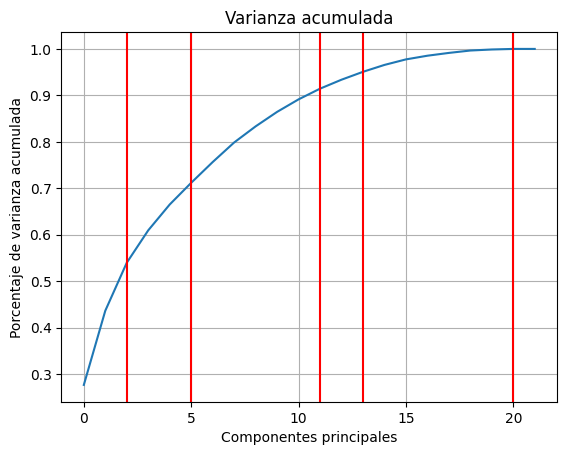

In [ ]:
# aca realizamos una curva de varianza explicada del PCA
pca_varianza = PCA(n_components=x.shape[1]).fit(StandardScaler().fit_transform(x))
plt.plot(np.cumsum(pca_varianza.explained_variance_/np.sum(pca_varianza.explained_variance_)))
plt.axvline(x=2.0, c= 'r')
plt.axvline(x=5.0, c= 'r')
plt.axvline(x=13, c= 'r')
plt.axvline(x=11, c= 'r')
plt.axvline(x=20, c= 'r')
plt.title('Varianza acumulada')
plt.xlabel('Componentes principales')
plt.ylabel('Porcentaje de varianza acumulada')
plt.grid()

Ahora recordemos que PCA también nos sirve para explorar y visualizar los datos en pocas dimensiones. En la siguiente celda vamos a visualizar nuestro conjunto de datos usando los dos primeros componentes principales

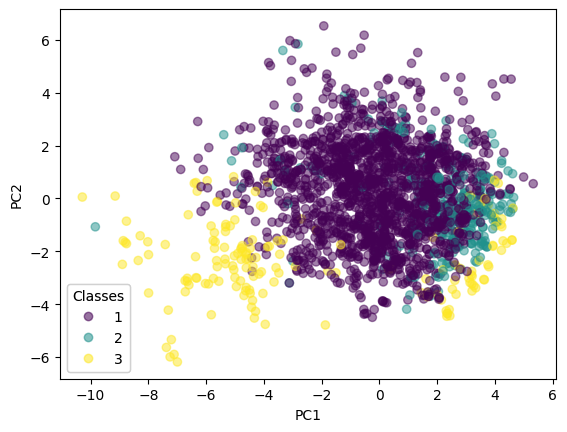

In [ ]:
data_to_plot = StandardScaler().fit_transform(X=x)
fig, ax = plt.subplots()
pca = PCA(n_components=2)
x_pc2 = pca.fit_transform(data_to_plot)
scatter= ax.scatter(x= x_pc2[:,0], y = x_pc2[:,1], c = y, alpha = 0.5, label = y)
legend1 = ax.legend(*scatter.legend_elements(),
                    loc="lower left", title="Classes")
ax.add_artist(legend1)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

In [ ]:
#@title Pregunta Abierta
#@markdown Aunque PCA nos nos ofrece una visualización aproximada de nuestro conjunto de datos, conociendo la varianza acumulada obtenida para 2 componentes principales ¿qué tan cercana es la aproximación para este problema en específico?
respuesta = '' #@param {type:"string"}

En nuestros laboratorios anteriores, hemos usado el siguiente código:

In [ ]:
digits = load_digits(n_class=5)
#--------- preprocesamiento--------------------
pca = PCA(n_components = 0.99, whiten=True)
print("shape antes pca", digits.data.shape)
data = pca.fit_transform(digits.data)
print("shape luego pca", data.shape)

shape antes pca (901, 64)
shape luego pca (901, 40)


Aplicando los conceptos que manejamos en este laboratorio, responde la siguiente pregunta abierta

In [ ]:
#@title Pregunta Abierta
#@markdown En nuestros laboratorios pasados y usando el código ejecutado anteriormente ¿Las 40 características representaban bien la varianza del conjunto original?
respuesta = '' #@param {type:"string"}

### Ejercicio 3: Entrenamiento usando Discriminante de Fisher para extracción

En este ejercicio vamos a aplicar LDA para realizar la extracción de características. Para ello tener en cuenta:

1. Vamos a usar el modulo [LinearDiscriminantAnalysis-LDA de sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html). El cual ya se encuentra importado (se pueda acceder a el como `LinearDiscriminantAnalysis(....)`)
2. ¿También se estandarizar los datos?
3. Usar 5 particiones en la metodologia de validación
3. Usar la exactitud/accuracy como medida de desempeño del módulo [metrics de sklearn](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.metrics)
4. Vamos a calcular el costo computacional de aplicar la LDA.
5. Recordar que LDA se debe "ajustar" con el conjunto de entrenamiento. Pero la transformación se debe hacer para las particiones de entrenamiento y test.

In [ ]:
#@title Pregunta Abierta
#@markdown Explicar en sus palabras la principal ventaja que tiene LDA sobre PCA para resolver problemas de clasificación.
respuesta = '' #@param {type:"string"}

In [ ]:
#ejercicio de código
def entrenamiento_lda_ext_caracteristicas(n_comp, X, Y):
    """
    Esta función realiza la reducción de la dimensionalidad sobre el conjunto de
    datos de entrenamiento, de acuerdo con las particiones especificadas usando PCA

    Parámetros:
        n_comp, int, Número de componentes para reducción
        X: numpy Array de características
        Y: numpy Array  Vector de etiquetas

    Retorna:
        tupla con:
        El  valor medio del tiempo de ejecución,
        El valor medio de exactitud
        Intervalo de confianza de la exactitud
    """


    #Implemetamos la metodología de validación
    Errores = np.ones(5)
    times = np.ones(5)
    j = 0
    kf = KFold(n_splits=5)
    for train_index, test_index in kf.split(X):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = Y[train_index], Y[test_index]

        # ¿es necesario estandarizacion de datos?
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
        # dejar el nombre del objeto igual (lda)
        lda = LinearDiscriminantAnalysis(n_components=n_comp)
        # para calcular costo computacional
        tiempo_i = time.time()
        # es recomendable usar el metodo que ajusta y transforma
        X_train_lda = lda.fit_transform(X_train, y_train)
        # aca solo usar el metodo de transformar (ya que en el anterior el pca se ajusto)
        X_test_lda = lda.transform(X_test)
        # entrenar el modelo usando las caractieristicas transformadas por PCA
        clf = SVC(kernel="linear", C=1)
        clf.fit(X=X_train_lda, y=y_train)
        tiempo_o = time.time()-tiempo_i
        Errores[j] = accuracy_score(y_true=y_test, y_pred=clf.predict(X_test_lda))
        times[j] = tiempo_o
        j+=1


    return np.mean(times), np.mean(Errores), np.std(Errores)

**Registra tu solución en línea**

In [ ]:
student.submit_task(namespace=globals(), task_id='T3');

### Ejercicio 4 : Experimentar con Discriminante de Fisher

Usando las anteriores funciones vamos a realizar experimentos para evaluar la efectividad de PCA, para ello:

1. Utilizar una metodología cross-validation con 5 particiones.
2. Usar como parámetros para los experimentos el número de características a extraer
3. Usar la función `entrenamiento_pca_ext_caracteristicas` para realizar la extración de características.
3. Vamos a retornar un DataFrame con las siguientes columnas:
    - CON_SEL: indicando si se uso selección de características
    - NUM_VAR: número de selección de caracteristicas
    - ERROR_VALIDACION
    - STD_ERROR_VALIDACION
    - T_EJECUCION: tiempo de ejecucción
4. En la primera fila del dataframe vamos a incluir la evaluación del modelo SVM sin selección de características (usando la función creada en el primer ejercicio).

In [ ]:
#ejercicio de código
def experimentar_LDA(n_feats, X, Y):
    """
    Esta función realiza la comparación del desempeño de LDA utilizando diferente
    número de feats y particionando el conjunto de datos en diferente en 5 subconjuntos

    Parámetros:
    X (numpy.array), El arreglo numpy de características
    Y (numpy.array), El vector de etiquetas
    n_feats, Vector de números enteros que indica el número de características
              que debe utilizar el modelo

    Retorna:
    - DataFrame con las columnas: CON_SEL, NUM_VAR, ERROR_VALIDACION, IC_STD_VALIDACION,
    y T_EJECUCION.

    """

    df = pd.DataFrame()
    idx = 0
    split_number = 5
    #Sin selección de características
    error, ic_error, t_ex = entrenamiento_sin_seleccion_caracteristicas(split_number, X, Y)
    df.loc[idx,'CON_SEL'] = 'NO'
    df.loc[idx,'NUM_VAR'] = X.shape[1]
    df.loc[idx,'ERROR_VALIDACION'] = 1 - error
    df.loc[idx,'STD_ERROR_VALIDACION'] = ic_error
    df.loc[idx,'T_EJECUCION'] = t_ex
    idx+=1
    print("termina experimento sin selección")
    #Con selección de características

    for f in n_feats:
        #Implemetamos la metodología de validación
        t_ex, error, ic_error = entrenamiento_lda_ext_caracteristicas(n_comp=f, X=X, Y=Y)
        df.loc[idx,'CON_SEL'] = 'SI'
        df.loc[idx,'NUM_VAR'] = f
        df.loc[idx,'ERROR_VALIDACION'] = 1 - error
        df.loc[idx, 'STD_ERROR_VALIDACION'] = ic_error
        df.loc[idx, 'T_EJECUCION'] = t_ex
        idx+=1
    return df

**Registra tu solución en línea**

In [ ]:
student.submit_task(namespace=globals(), task_id='T4');

In [ ]:
experimentar_LDA(n_feats=[1,2], X= x, Y = y)